# 3-fish recording: good-frame accuracy with a tighter mask-length limit

The mask QC of `EOD_assignment_3_fish_silent.ipynb` keeps a fish's mask when its principal-axis length is 0.7–1.2 × that fish's
median. EOD row 17707 (`EOD_debug_single_3fish.ipynb`) passed at 0.744: fish 0 lay along the wall with ~3–4 cm of its body missing
from the mask, and the assignment went wrong. Here the lower limit is raised to **0.8**, as a comparison only (the existing good
frames and results are not changed):

- **good frames**: as before (`common_good_frames.csv`: mask QC and SLEAP both good, 6,938 EODs);
- **better list**: those frames where every fish's mask is at least 0.8 × that fish's median length (the QC applies its limits to
  every fish), saved as `results/eod_ground_truth_3fish/good_frames_better_list.csv` (same format as `common_good_frames.csv`).

Lengths and medians are computed as in the QC (`mask_metrics.shape_metrics`, median over all frames where the fish has a mask).
Accuracy (% of EODs assigned to fish 0) for the four variants of my model (sign fixed), Denis' latest run with his own midline and
with my mask midline, from `results/eod_ground_truth_3fish/conductivities/eod_assignments.csv`.

In [1]:
import pickle
import numpy as np
import pandas as pd
import mask_metrics as mm
%matplotlib inline
import matplotlib.pyplot as plt

TRACK_PKL = 'data/3_fish_silent/elephantnose_20241015T141225_tracking_final.pkl'
OUT = 'results/eod_ground_truth_3fish/conductivities'
FISH, EMITTER = (0, 1, 2), 0
LENGTH_MIN_OLD, LENGTH_MIN_NEW = 0.7, 0.8

with open(TRACK_PKL, 'rb') as f:
    frames = pickle.load(f)['frames']
rows = []
for k, fr in frames.items():
    for l, p, b in zip(fr['labels'], fr['masks'], fr['boxes']):
        if l in FISH: rows.append(dict(frame=k, fish=l, **mm.shape_metrics(mm.unpack_crop(p, b), b)))
q = pd.DataFrame(rows)
q['length_ratio'] = q.major / q.groupby('fish').major.transform('median')
L = q.pivot_table(index='frame', columns='fish', values='length_ratio', aggfunc='min')   # (frame, fish) length / median
print('median principal-axis length (px):', q.groupby('fish').major.median().round(1).to_dict())

median principal-axis length (px): {0: 158.2, 1: 225.7, 2: 189.5}


In [2]:
A = pd.read_csv(f'{OUT}/eod_assignments.csv', index_col='row')
pipes = [c for c in A.columns if c.startswith('fish | ')]
lr = L.reindex(A.Frame.to_numpy())
lr.index = A.index
good = A['good frames'].to_numpy()
assert (lr[good].min(axis=1) >= LENGTH_MIN_OLD - 1e-9).all()          # the existing good frames already pass 0.7 for every fish
better = good & (lr.min(axis=1) >= LENGTH_MIN_NEW).to_numpy()
common = pd.read_csv('results/eod_ground_truth_3fish/common_good_frames.csv').frame
assert set(A.Frame[good]) == set(common)
better_frames = np.sort(A.Frame[better].unique())
pd.Series(better_frames, name='frame').to_csv('results/eod_ground_truth_3fish/good_frames_better_list.csv', index=False)
print(f'good_frames_better_list.csv: {len(better_frames)} of {len(common)} common good frames '
      f'({good.sum() - better.sum()} of {good.sum()} EODs dropped); '
      f'fish 0 limit only would keep {(good & (lr[EMITTER] >= LENGTH_MIN_NEW).to_numpy()).sum()} EODs')
SETS = {'good frames': good, 'better list': better}
acc = pd.DataFrame({f'{s} (n = {m.sum()})': [100 * (A.loc[m, c] == EMITTER).mean() for c in pipes] for s, m in SETS.items()},
                   index=[c.replace('fish | ', '') for c in pipes]).rename_axis('% correct (fish 0)')
removed = good & ~better
acc[f'dropped (n = {removed.sum()})'] = [100 * (A.loc[removed, c] == EMITTER).mean() for c in pipes]
acc.to_csv(f'{OUT}/accuracy_length_limit_{LENGTH_MIN_NEW}.csv')
display(acc.round(2))
print(f"saved {OUT}/accuracy_length_limit_{LENGTH_MIN_NEW}.csv")

good_frames_better_list.csv: 6696 of 6879 common good frames (187 of 6938 EODs dropped); fish 0 limit only would keep 6764 EODs


,good frames (n = 6938),better list (n = 6751),dropped (n = 187)
% correct (fish 0),,,
"previous σ (interior 200, skin 0.05, 0.2 cm), sink at tail tip",94.47,94.70,86.10
"previous σ (interior 200, skin 0.05, 0.2 cm), sink 5% from tail tip",93.57,93.82,84.49
"BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip",94.26,94.50,85.56
"BEM σ (interior 100, skin 0.05, 0.005 cm), sink 5% from tail tip",93.57,93.81,85.03
Denis' pipeline (latest run),93.89,94.07,87.17
Denis' pipeline with my mask midline,94.94,95.20,85.56


saved results/eod_ground_truth_3fish/conductivities/accuracy_length_limit_0.8.csv


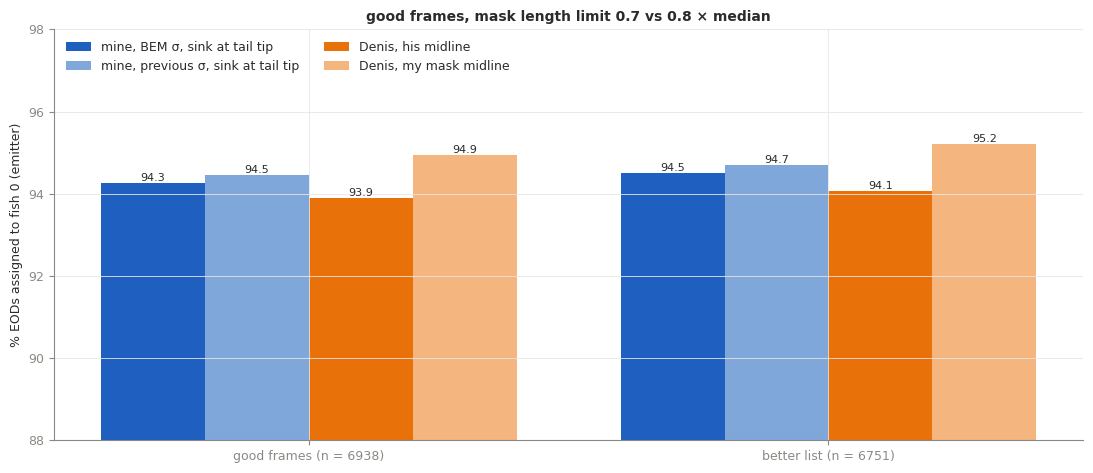

In [3]:
show = {"mine, BEM σ, sink at tail tip": 'BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip',
        "mine, previous σ, sink at tail tip": 'previous σ (interior 200, skin 0.05, 0.2 cm), sink at tail tip',
        "Denis, his midline": "Denis' pipeline (latest run)", "Denis, my mask midline": "Denis' pipeline with my mask midline"}
col = {"mine, BEM σ, sink at tail tip": '#1F5FBF', "mine, previous σ, sink at tail tip": '#7FA7D9',
       "Denis, his midline": '#E8710A', "Denis, my mask midline": '#F5B57F'}
fig, ax = plt.subplots(figsize=(11, 4.8))
x, w = np.arange(len(SETS)), 0.2  # one group per frame list
for j, (nm, c) in enumerate(show.items()):
    b = ax.bar(x + (j - 1.5) * w, acc.loc[c].iloc[:len(SETS)], w, color=col[nm], label=nm)
    ax.bar_label(b, fmt='%.1f', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(acc.columns[:len(SETS)])
ax.set(ylim=(88, 98), ylabel='% EODs assigned to fish 0 (emitter)', title=f'good frames, mask length limit {LENGTH_MIN_OLD} vs {LENGTH_MIN_NEW} × median')
ax.legend(fontsize=9, ncol=2, loc='upper left')
plt.tight_layout(); fig.savefig(f'{OUT}/figures/accuracy_length_limit.png', dpi=110); plt.show()

## Summary

`good_frames_better_list.csv`: 6,696 of the 6,879 common good frames (6,751 of 6,938 EODs), every fish's mask ≥ 0.8 × its median
length. Limiting fish 0 alone would keep 6,764 EODs, with accuracies within 0.02 points of these.

| pipeline | good frames (6,938) | better list (6,751) | dropped (187) |
|---|---|---|---|
| mine, previous σ, sink at tail tip | 94.47 | **94.70** | 86.10 |
| mine, previous σ, sink 5% in | 93.57 | 93.82 | 84.49 |
| mine, BEM σ, sink at tail tip | 94.26 | **94.50** | 85.56 |
| mine, BEM σ, sink 5% in | 93.57 | 93.81 | 85.03 |
| Denis, his midline (latest run) | 93.89 | **94.07** | 87.17 |
| Denis, my mask midline | 94.94 | **95.20** | 85.56 |

- The dropped EODs are hard for every pipeline (84–87% correct), so every pipeline gains 0.2–0.3 points; the order is unchanged.
- On the better list my model (sink at tail tip) is ahead of Denis with his own midline by 0.4–0.6 points; Denis with my mask midline
  is highest, 0.5 points above my best variant.